# Step 5: Model Evaluation & Metrics Reporting

Computes:
- **Accuracy, Precision, Recall, F1-Score, and ROC-AUC** on the held-out test set
- Generates and saves **Confusion Matrix Heatmap**
- Generates and saves **ROC Curve**
- Saves JSON and text evaluation reports in `evaluation/`

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import Wav2Vec2Model
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report

BASE_DIR = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_PROCESSED_DIR = BASE_DIR / "data" / "processed_clean"
EVALUATION_DIR = BASE_DIR / "evaluation"
MODELS_DIR = BASE_DIR / "models"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"


e:\Deepfake\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load Model and Test Set
checkpoint = torch.load(MODELS_DIR / "best_wav2vec2_deepfake_model.pth", map_location=device, weights_only=False)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.wav2vec2 = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base")
        self.classifier = nn.Sequential(
            nn.LayerNorm(768),
            nn.Linear(768, 256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )
    def forward(self, input_values):
        out = self.wav2vec2(input_values=input_values)
        return torch.softmax(self.classifier(out.last_hidden_state.mean(dim=1)), dim=-1)

model = Classifier().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_df = pd.read_csv(DATA_PROCESSED_DIR / "test_split.csv")
print(f"Loaded {len(test_df)} test samples.")


Loading weights: 100%|██████████| 211/211 [00:00<00:00, 18988.52it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.weight             | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded 450 test samples.


In [3]:
# Run Inference on Test Set
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for _, row in test_df.iterrows():
        y, _ = sf.read(row["proc_path"], dtype="float32")
        if y.ndim > 1: y = y.mean(axis=1)
        if len(y) < 64000: y = np.pad(y, (0, 64000 - len(y)))
        else: y = y[:64000]
        
        t_y = torch.from_numpy(y).unsqueeze(0).to(device)
        probs = model(t_y).cpu().numpy()[0]
        
        all_probs.append(probs[1])
        all_preds.append(np.argmax(probs))
        all_labels.append(row["label_id"])

all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)
cm = confusion_matrix(all_labels, all_preds)

print("="*60)
print(f"Test Accuracy:  {acc*100:.2f}%")
print(f"Test Precision: {prec*100:.2f}%")
print(f"Test Recall:    {rec*100:.2f}%")
print(f"Test F1-Score:  {f1*100:.2f}%")
print(f"Test ROC-AUC:   {auc*100:.2f}%")
print("="*60)


Test Accuracy:  98.44%
Test Precision: 98.23%
Test Recall:    98.67%
Test F1-Score:  98.45%
Test ROC-AUC:   99.79%


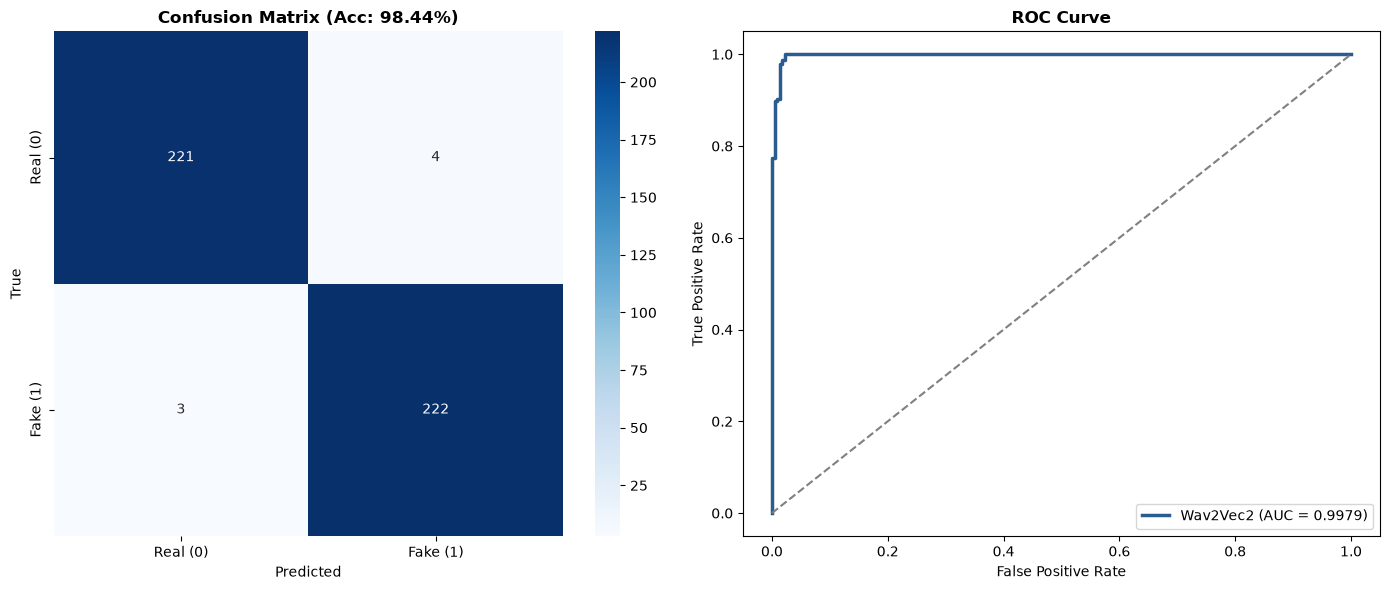

In [4]:
# Plot Confusion Matrix and ROC Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax1,
            xticklabels=["Real (0)", "Fake (1)"], yticklabels=["Real (0)", "Fake (1)"])
ax1.set_title(f"Confusion Matrix (Acc: {acc*100:.2f}%)", fontweight="bold")
ax1.set_xlabel("Predicted")
ax1.set_ylabel("True")

# ROC Curve
fpr, tpr, _ = roc_curve(all_labels, all_probs)
ax2.plot(fpr, tpr, color="#2b5c8f", lw=2.5, label=f"Wav2Vec2 (AUC = {auc:.4f})")
ax2.plot([0, 1], [0, 1], color="gray", linestyle="--")
ax2.set_title("ROC Curve", fontweight="bold")
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.legend()

plt.tight_layout()
plt.savefig(EVALUATION_DIR / "confusion_matrix.png", dpi=300)
plt.show()
